# Reproducing MiniRocket's scalability experiments

**Jacob Antonio and Uchhas Dewan, University College Dublin**

This notebook documents our reproduction of the scalability experiments in Section 4.2 of Dempster, Schmidt and Webb (2021), *MiniRocket: A Very Fast (Almost) Deterministic Transform for Time Series Classification*. The paper reports two experiments, and we reproduced both:

1. **Training set size.** MiniRocket is paired with a logistic regression classifier, trained with Adam, on the three largest datasets in the UCR archive: InsectSound, FruitFlies and MosquitoSound. Training time is recorded at increasing training set sizes. We used the repository's own training script, `softmax.py`, with its default settings, including its 2,048-example validation set.
2. **Series length.** MiniRocket is paired with a ridge classifier on DucksAndGeese, whose series are 236,784 points long. Training time is recorded as the series are truncated to increasing lengths.

The sweep points (training set sizes and series lengths) and the authors' measured training times are taken directly from the repository's `time_training_<dataset>.csv` files, which serve as our reference. This notebook is separate from our reproduction of the 109-dataset UCR accuracy benchmark.

**Departures from the authors' setup.** Our timings were measured on an Apple Silicon laptop rather than the authors' cluster, so absolute times are not directly comparable. The classifier in `softmax.py` is trained on randomly ordered minibatches, so we fixed the PyTorch seed at each sweep point to make our runs traceable. The authors report a single run per point, and run-to-run numbers can differ from theirs. MiniRocket's own bias sampling uses Numba's internal random number generator, which ordinary NumPy and Python seeds do not control.

**Data preparation.** `softmax.py` reads a CSV format with the integer class label in the first column, which the datasets are not distributed in, and the largest source files (MosquitoSound, 4.5 GB per split) are too large to load into memory on our machine. Section 2 therefore converts each dataset row by row into the required format, without holding a full split in memory. The original train/test split and data values are kept unchanged.

**Outputs.** We saved the converted CSVs, the training-set shuffle order, the class-label mappings, per-point accuracy and timing results, plots, and experiment metadata. The saved data and shuffle orders allow our improved methods to be evaluated on exactly the same examples as this baseline.

**Supplementary sections.** Sections 7 and 8 were added after the experiments were run. They read only the saved metadata and result files, so they can be run on their own, in a fresh session, without repeating any experiment.

In [1]:
from pathlib import Path
import csv
import gc
import importlib
import json
import platform
import random
import shutil
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import numba
from aeon.datasets import load_from_ts_file
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score
from threadpoolctl import threadpool_limits

# Project folder and cloned MiniRocket repository on the machine used for our runs.
PROJECT = Path("/Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series")
REPO = PROJECT / "minirocket"
CODE_DIR = REPO / "code"
REFERENCE_DIR = REPO / "results"

# The separately downloaded scalability datasets are stored under this folder.
DATA_ROOT = PROJECT / "minirocket_scalability_data"
PREP_DIR = PROJECT / "minirocket_scalability_prepared"
RESULTS_DIR = PROJECT / "minirocket_scalability_results_full_cache"
PREP_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

NUM_FEATURES = 10_000
VALIDATION_SIZE = 2 ** 11  # 2,048, as in the repository's softmax.py
CHUNK_SIZE = 2 ** 12
MINIBATCH_SIZE = 256
LEARNING_RATE = 1e-4
MAX_EPOCHS = 50
PATIENCE_LR = 5
PATIENCE = 10
BASE_SEED = 2026

# None keeps the repository default of caching all transformed training features.
# This matches the paper's large-dataset workflow and needs substantial RAM.
CACHE_SIZE = None

for required in (PROJECT, REPO, CODE_DIR, REFERENCE_DIR):
    if not required.exists():
        raise FileNotFoundError(f"Required path not found: {required}")

print("Project:", PROJECT)
print("Data folder:", DATA_ROOT)
print("Prepared CSVs:", PREP_DIR)
print("Results:", RESULTS_DIR)
print("MiniRocket source:", CODE_DIR)
print("PyTorch threads before limiting:", torch.get_num_threads())

Project: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series
Data folder: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_data
Prepared CSVs: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_prepared
Results: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_results_full_cache
MiniRocket source: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket/code
PyTorch threads before limiting: 4


## 1. Locating the datasets

The four datasets were downloaded separately from the UCR/UEA archive and extracted under `minirocket_scalability_data`. This cell locates each dataset's training and test files, accepting either `.ts` or `.arff` format, and reports their sizes. It only checks filenames and file sizes, without reading the series into memory.

MosquitoSound is distributed as ARFF, at 4.5 GB per split. The other three datasets are in `.ts` format.

In [2]:
DATASET_NAMES = ["MosquitoSound", "InsectSound", "FruitFlies", "DucksAndGeese"]

# .ts is preferred when both formats are present; otherwise .arff is used.
def find_dataset_file(dataset_name, split):
    for suffix in (".ts", ".arff"):
        matches = sorted(DATA_ROOT.rglob(f"{dataset_name}_{split}{suffix}"))
        if matches:
            if len(matches) > 1:
                print(f"Warning: multiple {dataset_name}_{split}{suffix} files; using {matches[0]}")
            return matches[0]
    return None

# The DucksAndGeese experiment is small enough to load directly from its .ts files with aeon.
def find_ts_file(dataset_name, split):
    matches = sorted(DATA_ROOT.rglob(f"{dataset_name}_{split}.ts"))
    if len(matches) > 1:
        print(f"Warning: multiple {dataset_name}_{split}.ts files; using {matches[0]}")
    return matches[0] if matches else None

found_paths = {}
for dataset_name in DATASET_NAMES:
    print(f"\n{dataset_name}")
    found_paths[dataset_name] = {}
    for split in ("TRAIN", "TEST"):
        path = find_dataset_file(dataset_name, split)
        found_paths[dataset_name][split] = path
        if path is None:
            print(f"  {split}: not found (.ts or .arff)")
        else:
            size_gb = path.stat().st_size / (1024 ** 3)
            print(f"  {split}: {size_gb:.2f} GB — {path}")


MosquitoSound
  TRAIN: 4.54 GB — /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_data/MosquitoSound/MosquitoSound_TRAIN.arff
  TEST: 4.54 GB — /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_data/MosquitoSound/MosquitoSound_TEST.arff

InsectSound
  TRAIN: 0.16 GB — /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_data/InsectSound/InsectSound_TRAIN.ts
  TEST: 0.16 GB — /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_data/InsectSound/InsectSound_TEST.ts

FruitFlies
  TRAIN: 0.97 GB — /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_data/FruitFlies/FruitFlies_TRAIN.ts
  TEST: 0.97 GB — /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_data/FruitFlies/FruitFlies_TEST.ts

DucksAndGeese
  TRAIN: 0.13 GB — /Users/uchhasdewan

## 2. Preparing the inputs for the training set size experiment

The repository's `softmax.py` reads comma-separated rows of the form `integer_label,value_1,...,value_L`, and takes the **first 2,048 rows** of the training file as its validation set, using the rest for training. Following Appendix A of the paper, which shuffles the training set once, we shuffled each training set once with a fixed seed (2026). We saved the resulting order so that every training set size, and our later improvements, use the same validation and training examples. The test set is written in its original order.

Rather than loading each dataset into memory, the conversion first indexes the byte position of every row, then writes the rows one at a time in shuffled order. This keeps memory use small even for MosquitoSound, at the cost of needing free disk space roughly equal to the size of the source files.

In [3]:
def load_fixed_univariate_ts(path):
    """Load the small DucksAndGeese .ts split for its length experiment."""
    X, y = load_from_ts_file(str(path))
    X = np.asarray(X, dtype=np.float32)
    if X.ndim == 3 and X.shape[1] == 1:
        X = X[:, 0, :]
    elif X.ndim != 2:
        raise ValueError(f"Expected fixed-length univariate data; got shape {X.shape} from {path}")
    return X, np.asarray(y).astype(str)


def _parse_classification_row(raw_line, path):
    """Return (feature strings, class string) for a dense univariate TS or ARFF row."""
    line = raw_line.decode("utf-8-sig").strip()
    if not line or line.startswith("%"):
        return None

    suffix = Path(path).suffix.lower()
    if suffix == ".arff":
        fields = next(csv.reader([line]))
        if len(fields) < 2:
            raise ValueError(f"Malformed ARFF data row in {path}: {line[:100]}")
        values = [v.strip() for v in fields[:-1]]
        label = fields[-1].strip().strip("\"'")
    elif suffix == ".ts":
        fields = line.split(":")
        if len(fields) != 2:
            raise ValueError(f"Expected univariate fixed-length .ts row in {path}: {line[:100]}")
        values = [v.strip() for v in fields[0].split(",")]
        label = fields[1].strip().strip("\"'")
    else:
        raise ValueError(f"Unsupported data format: {path}")

    if any(v == "?" or v == "" for v in values):
        raise ValueError(f"Missing/empty feature encountered; MiniRocket input must be numeric: {path}")
    return values, label


def scan_classification_split(path):
    """Index rows by byte offset and collect labels without retaining the series."""
    path = Path(path)
    offsets = []
    labels = set()
    expected_width = None
    in_data = False

    with path.open("rb") as source:
        while True:
            offset = source.tell()
            raw_line = source.readline()
            if not raw_line:
                break
            stripped = raw_line.strip()
            if not in_data:
                if stripped.lower() == b"@data":
                    in_data = True
                continue
            parsed = _parse_classification_row(raw_line, path)
            if parsed is None:
                continue
            values, label = parsed
            if expected_width is None:
                expected_width = len(values)
            elif len(values) != expected_width:
                raise ValueError(f"Variable-length or inconsistent data found in {path}")
            offsets.append(offset)
            labels.add(label)

    if not in_data or not offsets:
        raise ValueError(f"No @data rows found in {path}")
    return np.asarray(offsets, dtype=np.uint64), labels, int(expected_width)


def write_indexed_rows_csv(source_path, offsets, row_indices, label_map, output_path):
    """Write label-first CSV by seeking one source row at a time."""
    source_path = Path(source_path)
    output_path = Path(output_path)
    temp_path = output_path.with_suffix(output_path.suffix + ".tmp")
    with source_path.open("rb") as source, temp_path.open("w", newline="") as target:
        writer = csv.writer(target, lineterminator="\n")
        for count, original_index in enumerate(row_indices, start=1):
            source.seek(int(offsets[int(original_index)]))
            parsed = _parse_classification_row(source.readline(), source_path)
            if parsed is None:
                raise ValueError(f"Unexpected blank row at indexed position in {source_path}")
            values, label = parsed
            if label not in label_map:
                raise ValueError(f"Label {label!r} is missing from the training label map")
            writer.writerow([label_map[label], *values])
            if count % 10_000 == 0:
                print(f"  wrote {count:,} rows to {output_path.name}", end="\r", flush=True)
    temp_path.replace(output_path)
    print(f"  wrote {len(row_indices):,} rows to {output_path.name}")


def prepare_large_dataset(dataset_name, shuffle_seed=BASE_SEED):
    train_path = find_dataset_file(dataset_name, "TRAIN")
    test_path = find_dataset_file(dataset_name, "TEST")
    if train_path is None or test_path is None:
        raise FileNotFoundError(
            f"Could not find {dataset_name}_TRAIN and/or {dataset_name}_TEST as .ts or .arff under {DATA_ROOT}."
        )

    train_csv = PREP_DIR / f"{dataset_name}_TRAIN_shuffled.csv"
    test_csv = PREP_DIR / f"{dataset_name}_TEST.csv"
    order_path = PREP_DIR / f"{dataset_name}_train_order_seed{shuffle_seed}.npy"
    map_path = PREP_DIR / f"{dataset_name}_class_map.json"
    prep_path = PREP_DIR / f"{dataset_name}_preparation.json"

    if train_csv.exists() and test_csv.exists() and order_path.exists() and map_path.exists() and prep_path.exists():
        print(f"Prepared files already exist for {dataset_name}; reusing them:")
        print(" ", train_csv)
        print(" ", test_csv)
        return json.loads(prep_path.read_text())

    required_bytes = train_path.stat().st_size + test_path.stat().st_size
    free_bytes = shutil.disk_usage(PREP_DIR).free
    if free_bytes < required_bytes:
        raise OSError(
            f"Not enough free disk space for safe conversion. Source files total "
            f"{required_bytes / 1024**3:.2f} GiB; free space is {free_bytes / 1024**3:.2f} GiB."
        )

    print(f"Indexing training rows from {train_path}")
    train_offsets, train_labels, train_length = scan_classification_split(train_path)
    print(f"  found {len(train_offsets):,} rows × {train_length:,} values")
    print(f"Indexing test rows from {test_path}")
    test_offsets, test_labels, test_length = scan_classification_split(test_path)
    print(f"  found {len(test_offsets):,} rows × {test_length:,} values")
    if train_length != test_length:
        raise ValueError("Train and test series lengths differ.")

    class_names = sorted(train_labels)
    if not test_labels.issubset(set(class_names)):
        raise ValueError("Test split contains a class label not present in the training split.")
    label_map = {label: i for i, label in enumerate(class_names)}

    order = np.random.default_rng(shuffle_seed).permutation(len(train_offsets))
    print(f"Writing shuffled training CSV (seed={shuffle_seed}) row by row...")
    write_indexed_rows_csv(train_path, train_offsets, order, label_map, train_csv)
    print("Writing test CSV in its original order row by row...")
    test_order = np.arange(len(test_offsets), dtype=np.int64)
    write_indexed_rows_csv(test_path, test_offsets, test_order, label_map, test_csv)

    np.save(order_path, order)
    map_path.write_text(json.dumps(label_map, indent=2))
    record = {
        "dataset": dataset_name,
        "source_train": str(train_path),
        "source_test": str(test_path),
        "source_train_bytes": train_path.stat().st_size,
        "source_test_bytes": test_path.stat().st_size,
        "train_cases": int(len(train_offsets)),
        "test_cases": int(len(test_offsets)),
        "series_length": train_length,
        "classes": class_names,
        "label_to_integer": label_map,
        "shuffle_seed": int(shuffle_seed),
        "validation_rows": int(VALIDATION_SIZE),
        "train_csv": str(train_csv),
        "test_csv": str(test_csv),
        "train_order_file": str(order_path),
        "preparation_method": "streaming row-by-row conversion; no full split loaded into RAM",
    }
    prep_path.write_text(json.dumps(record, indent=2))
    print(f"Prepared {dataset_name}: {train_csv} and {test_csv}")
    print(f"Saved row order and label map under {PREP_DIR}")
    return record



## 3. Loading the repository implementation and recording the setup

The DucksAndGeese series length experiment uses the standard MiniRocket `fit` and `transform` functions. The training set size experiment uses the repository's `softmax.py`, which streams the data in chunks and uses the validation set for learning-rate scheduling and early stopping.

We limited Numba and PyTorch to one thread each, matching the paper's single-core setup, and recorded the software versions, platform, repository commit and all training settings in `experiment_metadata.json`. The machine's installed memory was not captured at the time; it is added in Section 7.

In [4]:
sys.path.insert(0, str(CODE_DIR))
importlib.invalidate_caches()
import minirocket
import softmax

minirocket_fit = minirocket.fit
minirocket_transform = minirocket.transform
softmax_train = softmax.train
softmax_predict = softmax.predict

numba.set_num_threads(1)
torch.set_num_threads(1)

try:
    git_commit = __import__("subprocess").run(
        ["git", "-C", str(REPO), "rev-parse", "HEAD"],
        capture_output=True, text=True, check=True
    ).stdout.strip()
except Exception:
    git_commit = None

metadata = {
    "experiment": "MiniRocket scalability reproduction",
    "created_local_time": time.strftime("%Y-%m-%d %H:%M:%S"),
    "project": str(PROJECT),
    "repository": str(REPO),
    "repository_commit": git_commit,
    "python": sys.version,
    "platform": platform.platform(),
    "processor": platform.processor(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "torch": torch.__version__,
    "numba": numba.__version__,
    "aeon": __import__("aeon").__version__,
    "num_features": NUM_FEATURES,
    "validation_size": VALIDATION_SIZE,
    "chunk_size": CHUNK_SIZE,
    "minibatch_size": MINIBATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "max_epochs": MAX_EPOCHS,
    "patience_lr": PATIENCE_LR,
    "patience": PATIENCE,
    "cache_size_override": CACHE_SIZE,
    "numba_threads": numba.get_num_threads(),
    "torch_threads": torch.get_num_threads(),
    "base_seed_for_csv_shuffle_and_torch": BASE_SEED,
    "note": "Standard MiniRocket Numba internal random state may not be controlled by NumPy/Python seeds."
}
(RESULTS_DIR / "experiment_metadata.json").write_text(json.dumps(metadata, indent=2))
print(json.dumps(metadata, indent=2))


{
  "experiment": "MiniRocket scalability reproduction",
  "created_local_time": "2026-11-12 00:26:08",
  "project": "/Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series",
  "repository": "/Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket",
  "repository_commit": "0b1c245d9c9dbc50886f28bc7b32d5d45b5663d6",
  "python": "3.11.16 (main, Aug 27 2026, 14:37:43) [Clang 20.1.8 ]",
  "platform": "macOS-27.2-arm64-arm-64bit",
  "processor": "arm",
  "numpy": "2.3.5",
  "pandas": "3.0.6",
  "torch": "2.15.0",
  "numba": "0.63.1",
  "aeon": "1.6.0",
  "num_features": 10000,
  "validation_size": 2048,
  "chunk_size": 4096,
  "minibatch_size": 256,
  "learning_rate": 0.0001,
  "max_epochs": 50,
  "patience_lr": 5,
  "patience": 10,
  "cache_size_override": null,
  "numba_threads": 1,
  "torch_threads": 1,
  "base_seed_for_csv_shuffle_and_torch": 2026,
  "note": "Standard MiniRocket Numba internal random state may not be controlled by NumPy/Python s

## 4. Training set size experiment

The training set sizes are read from the repository's `time_training_<dataset>.csv` files, so our sweep points are identical to the authors'. At each size, we time the call to `softmax.train(...)`. As in the paper, this covers fitting MiniRocket, transforming the training and validation data, and training the classifier.

Test accuracy is evaluated once, at the full training set size, which is the accuracy reported in Table 2 of the paper. Smaller sizes are used only for the training time curve, so their test evaluations are skipped.

We kept the repository's default of caching all transformed training features in memory (`CACHE_SIZE = None`), so that each example is transformed only once. At the largest MosquitoSound size this cache is about 5.1 GiB. An earlier run of ours limited the cache to save memory, which forced the data to be re-transformed on every epoch and so changed the workload being timed. We therefore reran the experiments with the full cache and saved those results in a separate folder, `minirocket_scalability_results_full_cache`. All results in this notebook are from the full-cache run.

Results are saved after every sweep point, so an interrupted run resumes from the last completed point.

In [5]:
# Helper functions for the training set size sweep; each dataset is run in its own cell below.
def reference_training_sizes(dataset_name):
    path = REFERENCE_DIR / f"time_training_{dataset_name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Expected repository sweep file: {path}")
    ref = pd.read_csv(path)
    return ref["num_training_examples"].astype(int).tolist(), ref


def run_training_size_dataset(dataset_name):
    train_csv = PREP_DIR / f"{dataset_name}_TRAIN_shuffled.csv"
    test_csv = PREP_DIR / f"{dataset_name}_TEST.csv"
    prep_json = PREP_DIR / f"{dataset_name}_preparation.json"
    if not (train_csv.exists() and test_csv.exists() and prep_json.exists()):
        raise FileNotFoundError(f"Prepare {dataset_name} first using section 2.")
    prep = json.loads(prep_json.read_text())
    train_sizes, reference = reference_training_sizes(dataset_name)
    expected_original_train_cases = max(train_sizes) + VALIDATION_SIZE
    if prep["train_cases"] != expected_original_train_cases:
        print(
            f"WARNING: {dataset_name} has {prep['train_cases']:,} training cases, "
            f"but repository sweep points imply {expected_original_train_cases:,} "
            "including validation. This may be a newer/different dataset version; "
            "the run can proceed, but record this mismatch."
        )
    n_classes = len(prep["classes"])
    n_features_actual = 84 * (NUM_FEATURES // 84)

    output_csv = RESULTS_DIR / f"{dataset_name}_training_size_results.csv"
    if output_csv.exists():
        rows = pd.read_csv(output_csv).to_dict("records")
        completed_sizes = {int(row["training_examples_excluding_validation"]) for row in rows}
        print(f"Resuming {dataset_name}; {len(completed_sizes)} training-size points already saved.")
    else:
        rows = []
        completed_sizes = set()

    for point, training_size in enumerate(train_sizes):
        if training_size in completed_sizes:
            print(f"Skipping saved {dataset_name} point: {training_size:,} training examples")
            continue
        if training_size + VALIDATION_SIZE > prep["train_cases"]:
            raise ValueError(
                f"Training size {training_size} plus validation {VALIDATION_SIZE} exceeds available train cases."
            )
        requested_cache = training_size if CACHE_SIZE is None else int(CACHE_SIZE)
        cache_gib = requested_cache * n_features_actual * 4 / (1024 ** 3)
        print(f"\n{dataset_name}: training_size={training_size:,}; cache estimate={cache_gib:.2f} GiB")

        seed = BASE_SEED + point
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        train_kwargs = {
            "num_features": NUM_FEATURES,
            "validation_size": VALIDATION_SIZE,
            "chunk_size": CHUNK_SIZE,
            "minibatch_size": MINIBATCH_SIZE,
            "lr": LEARNING_RATE,
            "max_epochs": MAX_EPOCHS,
            "patience_lr": PATIENCE_LR,
            "patience": PATIENCE,
        }
        if CACHE_SIZE is not None:
            train_kwargs["cache_size"] = int(CACHE_SIZE)

        with threadpool_limits(limits=1):
            start = time.perf_counter()
            parameters, model, f_mean, f_std = softmax_train(
                str(train_csv), n_classes, int(training_size), **train_kwargs
            )
            training_seconds = time.perf_counter() - start

            # The paper's training-size curve times training at each size.
            # The full test set is evaluated only once, at the largest size, as in the paper's final accuracy report.
            is_full_size = training_size == max(train_sizes)
            if is_full_size:
                start = time.perf_counter()
                predictions, accuracy = softmax_predict(
                    str(test_csv), parameters, model, f_mean, f_std, score=True
                )
                test_seconds = time.perf_counter() - start
            else:
                predictions = None
                accuracy = np.nan
                test_seconds = np.nan

        ref_row = reference.loc[reference["num_training_examples"] == training_size].iloc[0]
        rows.append({
            "dataset": dataset_name,
            "training_examples_excluding_validation": int(training_size),
            "validation_examples": VALIDATION_SIZE,
            "test_examples": prep["test_cases"],
            "accuracy": float(accuracy) if np.isfinite(accuracy) else np.nan,
            "training_seconds_including_validation_transform": float(training_seconds),
            "test_transform_predict_seconds": float(test_seconds) if np.isfinite(test_seconds) else np.nan,
            "test_accuracy_evaluated": bool(is_full_size),
            "reference_training_seconds": float(ref_row["time_training_seconds"]),
            "torch_seed": int(seed),
            "num_features_requested": NUM_FEATURES,
            "num_features_actual": n_features_actual,
            "cache_size": requested_cache,
        })
        pd.DataFrame(rows).to_csv(output_csv, index=False)
        if is_full_size:
            print(
                f"full-size accuracy={accuracy:.4f}; training={training_seconds:.2f}s "
                f"(repository={ref_row['time_training_seconds']:.2f}s); "
                f"one-time full-test evaluation={test_seconds:.2f}s"
            )
        else:
            print(
                f"training={training_seconds:.2f}s "
                f"(repository={ref_row['time_training_seconds']:.2f}s); "
                "test set skipped for this training-size point"
            )
        del parameters, model, f_mean, f_std, predictions
        gc.collect()

    result = pd.DataFrame(rows)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(result["training_examples_excluding_validation"], result["training_seconds_including_validation_transform"], "o-", label="This run")
    axes[0].plot(result["training_examples_excluding_validation"], result["reference_training_seconds"], "s--", label="Repository reference")
    axes[0].set_xscale("log", base=2)
    axes[0].set_yscale("log")
    axes[0].set_xlabel("Training examples (validation excluded)")
    axes[0].set_ylabel("Training seconds")
    axes[0].set_title(f"{dataset_name}: training time")
    axes[0].grid(alpha=0.25)
    axes[0].legend()
    axes[1].plot(result["training_examples_excluding_validation"], result["accuracy"], "o-")
    axes[1].set_xscale("log", base=2)
    axes[1].set_xlabel("Training examples (validation excluded)")
    axes[1].set_ylabel("Test accuracy")
    axes[1].set_ylim(0, 1.02)
    axes[1].set_title(f"{dataset_name}: accuracy")
    axes[1].grid(alpha=0.25)
    fig.tight_layout()
    plot_path = RESULTS_DIR / f"{dataset_name}_training_size_plot.png"
    fig.savefig(plot_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return result

### Run 1: InsectSound

InsectSound has 25,000 training series of length 600, making it the smallest of the three workloads. It was run first, preparing the CSV inputs and then running the authors' six training set sizes.

At the full training size of 22,952 examples, test accuracy was 77.25% against the paper's 76.39%. Training took 29.5 s against the published 37.0 s.

Indexing training rows from /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_data/InsectSound/InsectSound_TRAIN.ts
  found 25,000 rows × 600 values
Indexing test rows from /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_data/InsectSound/InsectSound_TEST.ts
  found 25,000 rows × 600 values
Writing shuffled training CSV (seed=2026) row by row...
  wrote 25,000 rows to InsectSound_TRAIN_shuffled.csv
Writing test CSV in its original order row by row...
  wrote 25,000 rows to InsectSound_TEST.csv
Prepared InsectSound: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_prepared/InsectSound_TRAIN_shuffled.csv and /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_prepared/InsectSound_TEST.csv
Saved row order and label map under /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalabilit

/Users/uchhasdewan/miniconda3/envs/aeon-env/lib/python3.11/site-packages/torch/optim/lr_scheduler.py:1699: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  current = float(metrics)


training=5.00s (repository=5.05s); test set skipped for this training-size point

InsectSound: training_size=2,048; cache estimate=0.08 GiB
Training... (faster once caching is finished)
training=5.44s (repository=8.42s); test set skipped for this training-size point

InsectSound: training_size=4,096; cache estimate=0.15 GiB
Training... (faster once caching is finished)
training=8.52s (repository=12.38s); test set skipped for this training-size point

InsectSound: training_size=8,192; cache estimate=0.31 GiB
Training... (faster once caching is finished)
training=15.20s (repository=21.52s); test set skipped for this training-size point

InsectSound: training_size=16,384; cache estimate=0.61 GiB
Training... (faster once caching is finished)
Epoch 24; Chunk = 1...                                                          
<Stopped at Epoch 24>
training=23.16s (repository=32.86s); test set skipped for this training-size point

InsectSound: training_size=22,952; cache estimate=0.85 GiB
Traini

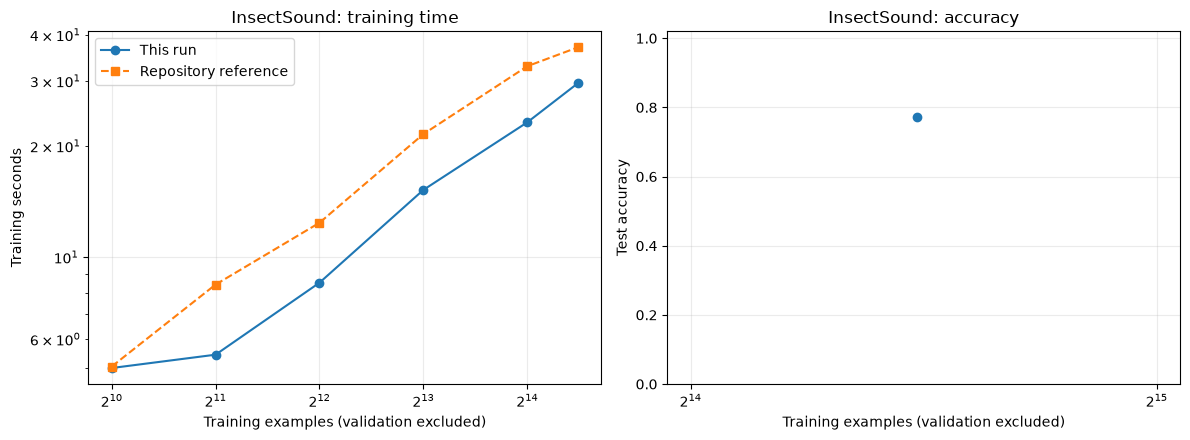

In [6]:
insect_preparation = prepare_large_dataset("InsectSound")
insect_training_results = run_training_size_dataset("InsectSound")


### Run 2: FruitFlies

FruitFlies has fewer training examples (17,259) than InsectSound, but its series are much longer (5,000 points), making it a heavier transform workload.

At the full training size of 15,211 examples, test accuracy was 95.17% against the paper's 95.68%. Training took 147.3 s against the published 141.7 s.

Indexing training rows from /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_data/FruitFlies/FruitFlies_TRAIN.ts
  found 17,259 rows × 5,000 values
Indexing test rows from /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_data/FruitFlies/FruitFlies_TEST.ts
  found 17,259 rows × 5,000 values
Writing shuffled training CSV (seed=2026) row by row...
  wrote 17,259 rows to FruitFlies_TRAIN_shuffled.csv
Writing test CSV in its original order row by row...
  wrote 17,259 rows to FruitFlies_TEST.csv
Prepared FruitFlies: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_prepared/FruitFlies_TRAIN_shuffled.csv and /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_prepared/FruitFlies_TEST.csv
Saved row order and label map under /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_pre

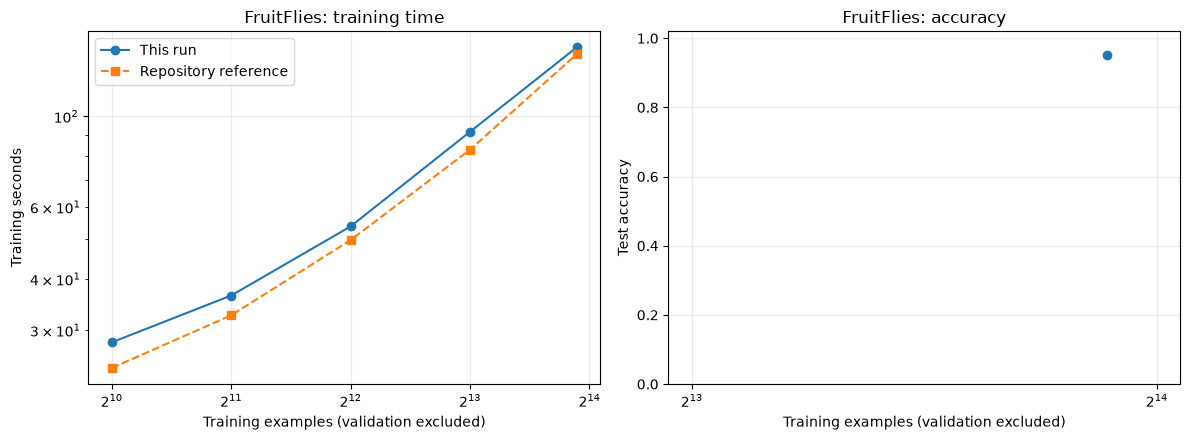

In [7]:
fruitflies_preparation = prepare_large_dataset("FruitFlies")
fruitflies_training_results = run_training_size_dataset("FruitFlies")


### Run 3: MosquitoSound

MosquitoSound is the largest workload, with 139,780 training series of length 3,750. Its CSV inputs had been prepared in an earlier session and were reused here.

Our training times stayed within 14% of the published ones up to 65,536 examples, but diverged at the two largest sizes: 1.67× the published time at 131,072 examples, and 1.82× at the full size of 137,732. Test accuracy at the full size was 75.17% against the paper's 81.65%.

The log helps explain the accuracy gap. At the full size, early stopping was triggered during the first epoch, which is why the `<Stopped at Epoch 1>` message repeats. `softmax.py` only acts on its stopping rule at the end of an epoch, so the classifier was trained for exactly one epoch, compared with four at 131,072 examples. The extra time is not explained by training, since the test evaluation alone, which involves no training, took a similar 1,351 s. The two slowest runs held the largest feature caches (about 4.9 and 5.1 GiB), which points to memory pressure or sustained-load slowdown of the laptop, although we could not isolate the cause.

Prepared files already exist for MosquitoSound; reusing them:
  /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_prepared/MosquitoSound_TRAIN_shuffled.csv
  /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_prepared/MosquitoSound_TEST.csv

MosquitoSound: training_size=1,024; cache estimate=0.04 GiB
Training... (faster once caching is finished)
training=20.47s (repository=18.18s); test set skipped for this training-size point

MosquitoSound: training_size=2,048; cache estimate=0.08 GiB
Training... (faster once caching is finished)
training=27.28s (repository=24.71s); test set skipped for this training-size point

MosquitoSound: training_size=4,096; cache estimate=0.15 GiB
Training... (faster once caching is finished)
training=40.31s (repository=37.87s); test set skipped for this training-size point

MosquitoSound: training_size=8,192; cache estimate=0.31 GiB
Training... (faster once caching is finis

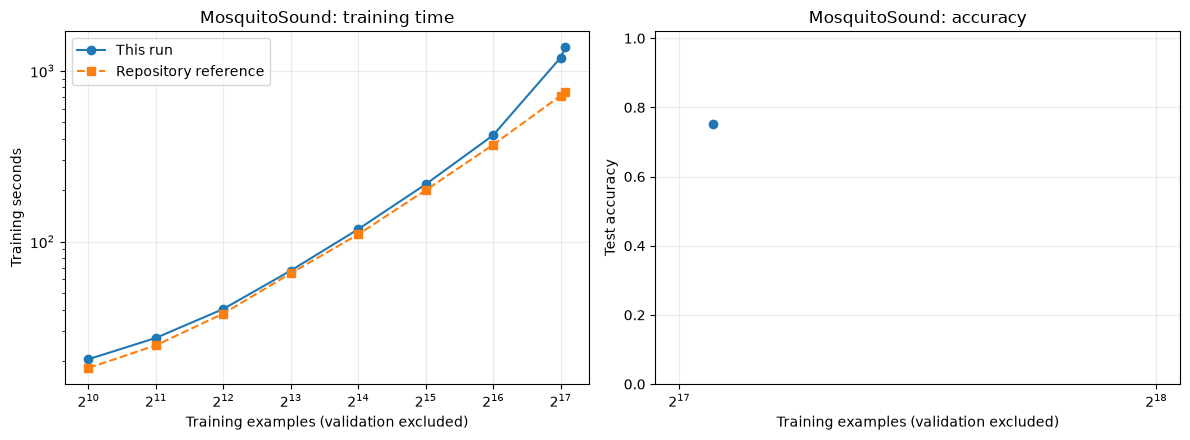

In [8]:
mosquito_preparation = prepare_large_dataset("MosquitoSound")
mosquito_training_results = run_training_size_dataset("MosquitoSound")


## 5. Series length experiment: DucksAndGeese

This experiment uses the original DucksAndGeese train/test split, with 50 training series of length 236,784. The series lengths are taken from the repository's `time_training_DucksAndGeese.csv`. The paper does not state how shorter series were produced, so we truncated each series to its first `L` points. At each length, we fit MiniRocket on the training data and train `RidgeClassifierCV` with the same α grid and feature normalisation as in our UCR benchmark.

Training time covers fitting MiniRocket, transforming the training set, normalising the features and training the classifier. Test transformation and prediction are timed separately. With only 50 training examples, this experiment does not use the 2,048-example validation procedure.

In [9]:
def l2_normalize_features(X_train_features, X_test_features):
    mean = X_train_features.mean(axis=0)
    X_train_features = X_train_features - mean
    X_test_features = X_test_features - mean
    scale = np.sqrt((X_train_features ** 2).sum(axis=0))
    scale[scale == 0] = 1.0
    return X_train_features / scale, X_test_features / scale


def run_ducks_length_experiment():
    train_path = find_ts_file("DucksAndGeese", "TRAIN")
    test_path = find_ts_file("DucksAndGeese", "TEST")
    if train_path is None or test_path is None:
        raise FileNotFoundError("Download and extract DucksAndGeese TRAIN and TEST .ts files first.")

    ref_path = REFERENCE_DIR / "time_training_DucksAndGeese.csv"
    if not ref_path.exists():
        raise FileNotFoundError(f"Expected repository sweep file: {ref_path}")
    ref = pd.read_csv(ref_path)
    lengths = ref["time_series_length"].astype(int).tolist()

    X_train, y_train = load_fixed_univariate_ts(train_path)
    X_test, y_test = load_fixed_univariate_ts(test_path)
    if X_train.shape[1] != X_test.shape[1]:
        raise ValueError("DucksAndGeese train/test series lengths differ.")
    if len(X_train) != 50:
        print(f"Warning: expected 50 training examples from the paper; found {len(X_train)}")

    rows = []
    result_path = RESULTS_DIR / "DucksAndGeese_series_length_results.csv"
    for L in lengths:
        if L > X_train.shape[1]:
            raise ValueError(f"Reference length {L} exceeds available series length {X_train.shape[1]}")
        Xtr = np.ascontiguousarray(X_train[:, :L], dtype=np.float32)
        Xte = np.ascontiguousarray(X_test[:, :L], dtype=np.float32)

        with threadpool_limits(limits=1):
            start = time.perf_counter()
            parameters = minirocket_fit(Xtr, num_features=NUM_FEATURES)
            Xt_train = minirocket_transform(Xtr, parameters)
            feature_mean = Xt_train.mean(axis=0)
            Xt_train = Xt_train - feature_mean
            feature_scale = np.sqrt((Xt_train ** 2).sum(axis=0))
            feature_scale[feature_scale == 0] = 1.0
            Xt_train = Xt_train / feature_scale
            classifier = RidgeClassifierCV(alphas=np.logspace(-3, 3, 10))
            classifier.fit(Xt_train, y_train)
            train_seconds = time.perf_counter() - start

            start = time.perf_counter()
            Xt_test = minirocket_transform(Xte, parameters)
            Xt_test = (Xt_test - feature_mean) / feature_scale
            predictions = classifier.predict(Xt_test)
            test_transform_predict_seconds = time.perf_counter() - start

        accuracy = accuracy_score(y_test, predictions)
        ref_seconds = float(ref.loc[ref["time_series_length"] == L, "time_training_seconds"].iloc[0])
        rows.append({
            "dataset": "DucksAndGeese",
            "series_length": int(L),
            "train_examples": int(len(X_train)),
            "test_examples": int(len(X_test)),
            "accuracy": float(accuracy),
            "training_seconds_fit_transform_ridge": float(train_seconds),
            "test_transform_predict_seconds": float(test_transform_predict_seconds),
            "reference_training_seconds": ref_seconds,
            "num_features_requested": NUM_FEATURES,
        })
        pd.DataFrame(rows).to_csv(result_path, index=False)
        print(f"length={L:,}; accuracy={accuracy:.3f}; training={train_seconds:.2f}s (repository={ref_seconds:.2f}s)")
        del Xtr, Xte, Xt_train, Xt_test, parameters, classifier, predictions
        gc.collect()

    result = pd.DataFrame(rows)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(result["series_length"], result["training_seconds_fit_transform_ridge"], "o-", label="This run")
    axes[0].plot(result["series_length"], result["reference_training_seconds"], "s--", label="Repository reference")
    axes[0].set_xscale("log", base=2)
    axes[0].set_yscale("log")
    axes[0].set_xlabel("Time-series length")
    axes[0].set_ylabel("Training seconds")
    axes[0].set_title("DucksAndGeese: training time")
    axes[0].grid(alpha=0.25)
    axes[0].legend()
    axes[1].plot(result["series_length"], result["accuracy"], "o-")
    axes[1].set_xscale("log", base=2)
    axes[1].set_xlabel("Time-series length")
    axes[1].set_ylabel("Test accuracy")
    axes[1].set_ylim(0, 1.02)
    axes[1].set_title("DucksAndGeese: accuracy")
    axes[1].grid(alpha=0.25)
    fig.tight_layout()
    plot_path = RESULTS_DIR / "DucksAndGeese_series_length_plot.png"
    fig.savefig(plot_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return result

# The DucksAndGeese experiment is run in the next cell.

### Run 4: DucksAndGeese

Our training times were within 8% of the published ones at every length except 8,192, where a single run took 3.61 s against 1.82 s. At the full length of 236,784, training took 66.5 s against 72.2 s published. From length 16,384 to 236,784, a 14.5-fold increase, our training time grew 15.8-fold. This is consistent with the paper's claim that MiniRocket's cost grows linearly with series length. The paper does not report accuracy for this experiment; ours was 30% at full length, from only 50 test examples.

length=1,024; accuracy=0.140; training=0.26s (repository=0.28s)
length=2,048; accuracy=0.240; training=0.45s (repository=0.43s)
length=4,096; accuracy=0.300; training=0.95s (repository=0.94s)
length=8,192; accuracy=0.320; training=3.61s (repository=1.82s)
length=16,384; accuracy=0.300; training=4.20s (repository=4.17s)
length=32,768; accuracy=0.360; training=8.47s (repository=8.86s)
length=65,536; accuracy=0.300; training=19.14s (repository=18.81s)
length=131,072; accuracy=0.400; training=37.72s (repository=38.88s)
length=236,784; accuracy=0.300; training=66.48s (repository=72.17s)


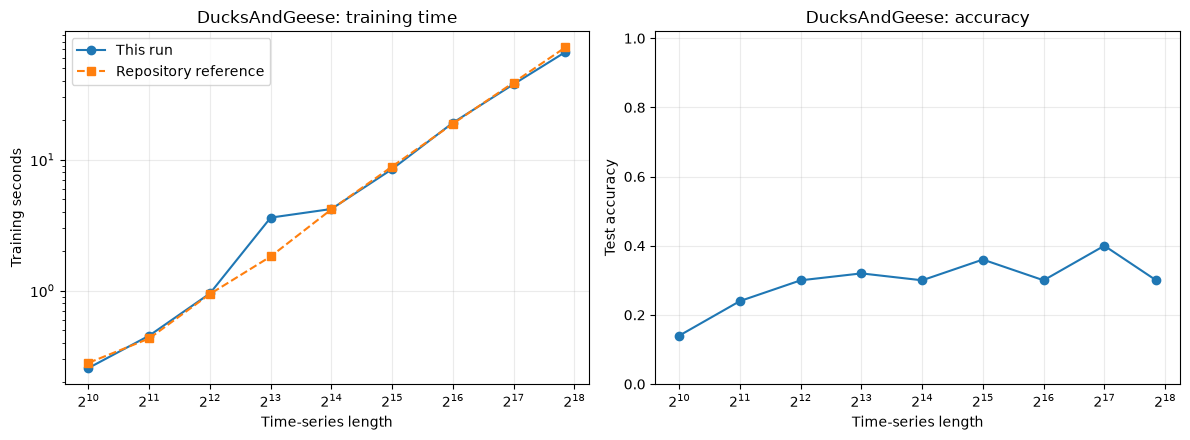

In [10]:
ducks_length_results = run_ducks_length_experiment()


## 6. How these results are reused in our improvement experiments

To compare our improved methods fairly with this baseline, we kept the prepared training CSVs and their saved shuffle orders (`*_train_order_seed2026.npy`) unchanged. This fixes which original examples form the validation and training sets at every size, and the test CSVs are likewise unchanged. Results for the improved methods are written to separate files, so the baseline results are never overwritten. For DucksAndGeese, the improved methods use the same original train/test data and the same length grid.

The repository reports a single run per sweep point, and so do we. Repeating each point with several PyTorch seeds, while keeping the same data order, would be a further robustness check but would go beyond an exact reproduction.

### Output files

- `minirocket_scalability_prepared/`: converted CSVs, saved shuffle orders, class maps and per-dataset preparation records.
- `minirocket_scalability_results_full_cache/experiment_metadata.json`: software, platform, repository commit and settings, with installed memory added in Section 7.
- `minirocket_scalability_results_full_cache/*_training_size_results.csv` and `DucksAndGeese_series_length_results.csv`: accuracy and timing at every sweep point, saved after each completed point.
- `minirocket_scalability_results_full_cache/*_plot.png`: our timings plotted against the repository's reference timings, with accuracy curves.
- `minirocket_scalability_results_full_cache/comparison_with_published.csv`: the summary comparison from Section 8.

## 7. Supplementary record: installed memory

The metadata recorded in Section 3 did not include the machine's installed memory, which is relevant to the MosquitoSound timings. This standalone cell adds it to `experiment_metadata.json`, together with a note that it was recorded after the experiments. It imports everything it needs and can be run on its own, without repeating any experiment.

In [2]:
import json
import os
import platform
import subprocess
import time
from pathlib import Path

PROJECT = Path("/Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series")
RESULTS_DIR = PROJECT / "minirocket_scalability_results_full_cache"
metadata_path = RESULTS_DIR / "experiment_metadata.json"
metadata = json.loads(metadata_path.read_text())

# Installed physical memory: sysctl on macOS, sysconf as a fallback elsewhere
try:
    memory_bytes = int(subprocess.run(["sysctl", "-n", "hw.memsize"],
                                      capture_output=True, text=True, check=True).stdout.strip())
except Exception:
    memory_bytes = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES")

# CPU model name on macOS, if available
try:
    cpu_model = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
                               capture_output=True, text=True, check=True).stdout.strip()
except Exception:
    cpu_model = platform.processor() or "not reported"

metadata["installed_memory_gib"] = round(memory_bytes / 1024**3, 1)
metadata["cpu_model"] = cpu_model
metadata["hardware_details_note"] = (
    "Installed memory and CPU model were recorded on "
    f"{time.strftime('%Y-%m-%d')}, after the experiments, on the same machine."
)
metadata_path.write_text(json.dumps(metadata, indent=2))
print(f"CPU: {cpu_model}")
print(f"Installed memory: {metadata['installed_memory_gib']} GiB")
print("Updated:", metadata_path)

CPU: Apple M1
Installed memory: 8.0 GiB
Updated: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_scalability_results_full_cache/experiment_metadata.json


## 8. Comparison with the published results

This standalone cell gathers our saved results into a single comparison with the authors' results. It reads only the saved result CSVs and the repository's reference files, so it can be run without repeating any experiment.

For each sweep point, it reports our training time, the published time and their ratio. For the full training sets, it compares our test accuracy with Table 2 of the paper. The repository's timing files do not include accuracy, so the published accuracies are taken from the paper itself.

In [3]:
from pathlib import Path

import pandas as pd

PROJECT = Path("/Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series")
RESULTS_DIR = PROJECT / "minirocket_scalability_results_full_cache"

# Test accuracy with the full training set, from Table 2 of Dempster et al. (2021)
PAPER_ACCURACY = {"InsectSound": 0.7639, "FruitFlies": 0.9568, "MosquitoSound": 0.8165}

rows = []
for dataset_name in ("InsectSound", "FruitFlies", "MosquitoSound"):
    result = pd.read_csv(RESULTS_DIR / f"{dataset_name}_training_size_results.csv")
    for _, row in result.iterrows():
        rows.append({
            "dataset": dataset_name,
            "sweep": "training set size",
            "point": int(row["training_examples_excluding_validation"]),
            "our_seconds": row["training_seconds_including_validation_transform"],
            "published_seconds": row["reference_training_seconds"],
            "our_accuracy": row["accuracy"],
            "published_accuracy": PAPER_ACCURACY[dataset_name] if row["test_accuracy_evaluated"] else float("nan"),
        })

ducks = pd.read_csv(RESULTS_DIR / "DucksAndGeese_series_length_results.csv")
for _, row in ducks.iterrows():
    rows.append({
        "dataset": "DucksAndGeese",
        "sweep": "series length",
        "point": int(row["series_length"]),
        "our_seconds": row["training_seconds_fit_transform_ridge"],
        "published_seconds": row["reference_training_seconds"],
        "our_accuracy": row["accuracy"],
        "published_accuracy": float("nan"),  # not reported in the paper
    })

comparison = pd.DataFrame(rows)
comparison["time_ratio_ours_over_published"] = comparison["our_seconds"] / comparison["published_seconds"]
comparison.to_csv(RESULTS_DIR / "comparison_with_published.csv", index=False)

pd.set_option("display.width", 140)
print("Training time at every sweep point:")
display(comparison[["dataset", "point", "our_seconds", "published_seconds", "time_ratio_ours_over_published"]].round(2))

full_size = comparison.dropna(subset=["published_accuracy"]).copy()
full_size["accuracy_difference_points"] = (full_size["our_accuracy"] - full_size["published_accuracy"]) * 100
print("\nFull training set results (Table 2 of the paper):")
display(full_size[["dataset", "point", "our_accuracy", "published_accuracy", "accuracy_difference_points",
                   "our_seconds", "published_seconds", "time_ratio_ours_over_published"]].round(4))

ducks_rows = comparison[comparison["dataset"] == "DucksAndGeese"].set_index("point")
length_growth = ducks_rows.index.max() / 16384
time_growth = ducks_rows.loc[ducks_rows.index.max(), "our_seconds"] / ducks_rows.loc[16384, "our_seconds"]
print(f"\nDucksAndGeese, length 16,384 to {ducks_rows.index.max():,}: "
      f"length grew {length_growth:.1f}x, our training time grew {time_growth:.1f}x")

Training time at every sweep point:


,dataset,point,our_seconds,published_seconds,time_ratio_ours_over_published
0,InsectSound,1024,5.00,5.05,0.99
1,InsectSound,2048,5.44,8.42,0.65
2,InsectSound,4096,8.52,12.38,0.69
3,InsectSound,8192,15.20,21.52,0.71
4,InsectSound,16384,23.16,32.86,0.70
5,InsectSound,22952,29.54,36.96,0.80
6,FruitFlies,1024,28.00,24.24,1.16
7,FruitFlies,2048,36.45,32.60,1.12
8,FruitFlies,4096,53.76,49.79,1.08
9,FruitFlies,8192,91.58,82.80,1.11



Full training set results (Table 2 of the paper):


,dataset,point,our_accuracy,published_accuracy,accuracy_difference_points,our_seconds,published_seconds,time_ratio_ours_over_published
5,InsectSound,22952,0.7725,0.7639,0.8620,29.5432,36.96,0.7993
10,FruitFlies,15211,0.9517,0.9568,-0.5065,147.2495,141.67,1.0394
19,MosquitoSound,137732,0.7517,0.8165,-6.4808,1371.6149,751.70,1.8247



DucksAndGeese, length 16,384 to 236,784: length grew 14.5x, our training time grew 15.8x
